# Subscription Retention & Churn Analytics

## Business Problem

Customer churn is one of the biggest challenges faced by subscription-based businesses, directly impacting recurring revenue and long-term growth. Understanding why customers cancel their subscriptions enables organizations to design effective retention strategies and improve customer lifetime value.

This project analyzes customer demographics, subscription details, and engagement behavior to identify the factors associated with churn. The analysis concludes with a Logistic Regression model to predict customers at risk of cancellation and provide actionable business recommendations.

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)
plt.style.use("default")
sns.set_theme(style="whitegrid")

df =pd.read_csv("../data/subscription_customer_churn.csv",)

# DATA PROFILING

In [68]:
df.shape



(5000, 14)

In [69]:
df.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


In [70]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   str    
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   str    
 3   subscription_type       5000 non-null   str    
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   str    
 7   device                  5000 non-null   str    
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   str    
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   str    
dtypes: float64(3), int64(4), str(7)
memory usage: 547.0

In [71]:
df.describe(include="all")


,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
count,5000,5000.000000,5000,5000,5000.000000,5000.000000,5000,5000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000
unique,5000,NaN,3,3,NaN,NaN,6,5,NaN,NaN,5,NaN,NaN,7
top,a9b75100-82a8-427a-a208-72f24052884a,NaN,Female,Premium,NaN,NaN,South America,Tablet,NaN,NaN,Debit Card,NaN,NaN,Drama
freq,1,NaN,1711,1693,NaN,NaN,873,1048,NaN,NaN,1030,NaN,NaN,731
mean,NaN,43.847400,NaN,NaN,11.649450,30.089800,NaN,NaN,13.683400,0.503000,NaN,3.024400,0.874800,NaN
std,NaN,15.501128,NaN,NaN,12.014654,17.536078,NaN,NaN,3.692062,0.500041,NaN,1.415841,2.619824,NaN
min,NaN,18.000000,NaN,NaN,0.010000,0.000000,NaN,NaN,8.990000,0.000000,NaN,1.000000,0.000000,NaN
25%,NaN,30.000000,NaN,NaN,3.337500,15.000000,NaN,NaN,8.990000,0.000000,NaN,2.000000,0.110000,NaN
50%,NaN,44.000000,NaN,NaN,8.000000,30.000000,NaN,NaN,13.990000,1.000000,NaN,3.000000,0.290000,NaN
75%,NaN,58.000000,NaN,NaN,16.030000,45.000000,NaN,NaN,17.990000,1.000000,NaN,4.000000,0.720000,NaN


In [72]:
df.isnull().sum()

customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64

In [73]:
df.duplicated().sum()

np.int64(0)

### Observations

- The dataset contains **5,000 customer records** with **14 features**, including demographic, subscription, and engagement-related information.
- The data consists of **7 categorical**, **4 integer**, and **3 numerical** columns.
- The target variable, **`churned`**, is present and suitable for binary classification.


## Data Cleaning

The dataset was examined for missing values, duplicate records, and inconsistent data types.

very less missing values or duplicate records were identified

In [74]:
df["churned"].value_counts()

churned
1    2515
0    2485
Name: count, dtype: int64

In [75]:
df["churned"].value_counts(normalize = True)*100

churned
1    50.3
0    49.7
Name: proportion, dtype: float64

Both classes are nearly equally represented

In [76]:
df.nunique()

customer_id               5000
age                         53
gender                       3
subscription_type            3
watch_hours               2343
last_login_days             61
region                       6
device                       5
monthly_fee                  3
churned                      2
payment_method               5
number_of_profiles           5
avg_watch_time_per_day     505
favorite_genre               7
dtype: int64

C:\Users\sprem\AppData\Local\Temp\ipykernel_15796\2673605929.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Retained","Churned"])


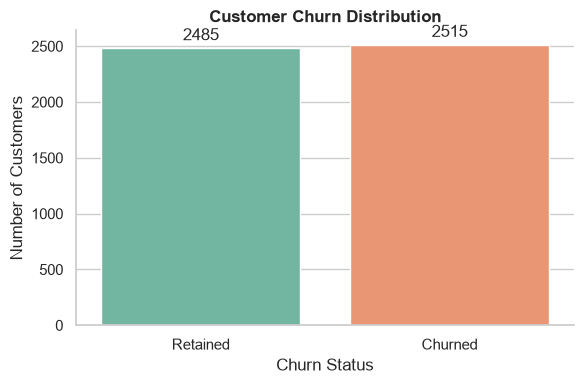

In [77]:
plt.figure(figsize=(6,4))

ax = sns.countplot(
    x="churned",
    data=df,
    hue = "churned",
    palette="Set2",
    legend = False
    )
plt.title("Customer Churn Distribution",weight="bold")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

ax.set_xticklabels(["Retained","Churned"])
for container in ax.containers:
    ax.bar_label(container, padding =3)
sns.despine()
plt.tight_layout()
plt.show()

# EXPLORATORY DATA ANALYSIS

## 1. AGE DISTRIBUTION

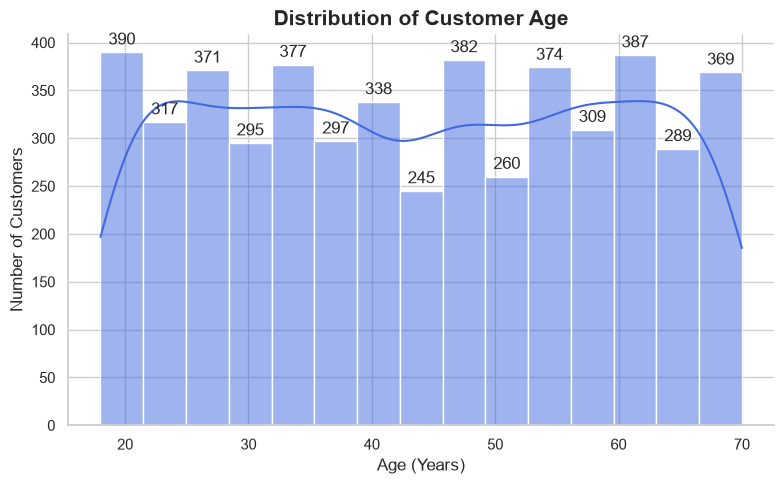

In [78]:
plt.figure(figsize=(8,5))

ax=sns.histplot(
    data = df,
    x = "age",
    bins = 15,
    kde=True,
    color="royalblue"
)
plt.title("Distribution of Customer Age", fontsize=15, weight="bold")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Customers")
for container in ax.containers:
    ax.bar_label(container, padding =3)
sns.despine()
plt.tight_layout()
plt.show()

The age distribution is fairly uniform across the observed age range. While the KDE curve exhibits minor local peaks, there is no strong concentration around a single age group or clear evidence of distinct age clusters.

In [79]:
df["age"].describe()

count    5000.000000
mean       43.847400
std        15.501128
min        18.000000
25%        30.000000
50%        44.000000
75%        58.000000
max        70.000000
Name: age, dtype: float64

### Observations
- Customer ages range from 18 to 70 years, with an average age of approximately 44 years.
- Age distribution is uniform as the **mean(43.83)** and the **median(44)** are close




## 2. Gender Distribution

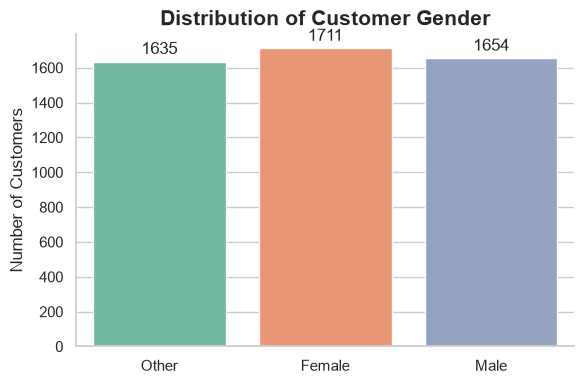

In [80]:
plt.figure(figsize=(6,4))

ax = sns.countplot(
    x = "gender",
    data = df,
    hue ="gender",
    palette="Set2",
    legend = False
)
plt.title("Distribution of Customer Gender", fontsize=15, weight="bold")
plt.xlabel("")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, padding=3)

sns.despine()

plt.tight_layout()
plt.show()

In [81]:
df["gender"].value_counts()

gender
Female    1711
Male      1654
Other     1635
Name: count, dtype: int64

In [82]:
df["gender"].value_counts(normalize =True)*100

gender
Female    34.22
Male      33.08
Other     32.70
Name: proportion, dtype: float64

#### Observations

- The customer base is almost evenly distributed across all three gender categories.
- Female customers account for **34.22%** of the dataset, followed by **Male (33.08%)** and **Other (32.70%)**.
- The differences between the three groups are minimal, indicating a well-balanced demographic distribution.

## 3. REGIONAL DISTRIBUTION

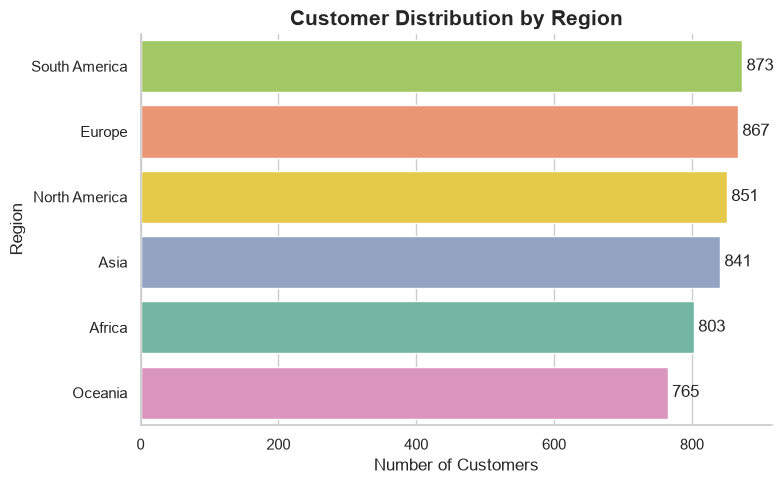

In [83]:
plt.figure(figsize=(8,5))


order = df["region"].value_counts().index
ax = sns.countplot(
    y="region",
    data=df,
    order=order,
    hue="region",
    palette="Set2",
    legend=False
)

plt.title("Customer Distribution by Region", fontsize=15, weight="bold")
plt.xlabel("Number of Customers")
plt.ylabel("Region")

for container in ax.containers:
    ax.bar_label(container, padding=3)

sns.despine()

plt.tight_layout()
plt.show()

In [84]:
order = df["region"].value_counts()
order

region
South America    873
Europe           867
North America    851
Asia             841
Africa           803
Oceania          765
Name: count, dtype: int64

#### Observations

- Customers are distributed fairly evenly across all six regions.
- South America has the highest number of customers (873), followed closely by Europe (867) and North America (851).
- Oceania has the smallest customer base (765), although the difference between regions is relatively small.

## 4. Subscription Analysis

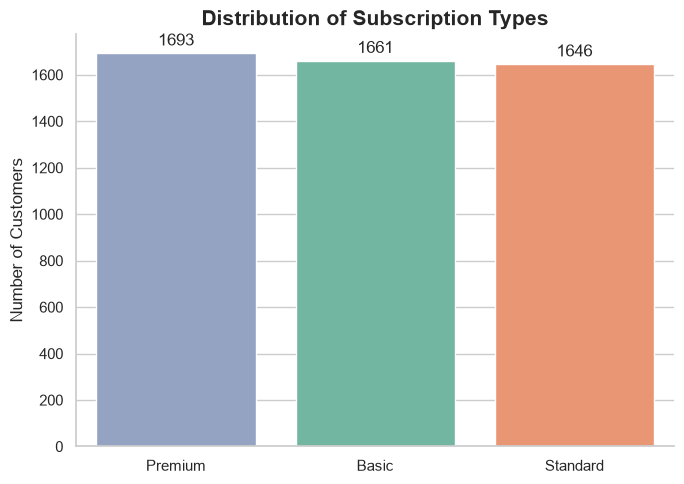

In [85]:
plt.figure(figsize=(7,5))

order = df["subscription_type"].value_counts().index

ax = sns.countplot(
    x="subscription_type",
    data=df,
    order=order,
    hue="subscription_type",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Subscription Types", fontsize=15, weight="bold")
plt.xlabel("")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, padding=3)

sns.despine()

plt.tight_layout()
plt.show()

In [86]:
df["subscription_type"].value_counts()

subscription_type
Premium     1693
Basic       1661
Standard    1646
Name: count, dtype: int64

In [87]:
df["subscription_type"].value_counts(normalize = True)*100

subscription_type
Premium     33.86
Basic       33.22
Standard    32.92
Name: proportion, dtype: float64

In [88]:
pd.crosstab(
    df["subscription_type"],
    df["monthly_fee"]
)

monthly_fee,8.99,13.99,17.99
subscription_type,,,
Basic,1661,0,0
Premium,0,0,1693
Standard,0,1646,0


#### Observations

- Subscription plans are almost evenly distributed across the customer base.
- Premium subscribers account for **33.86%** of customers, followed by **Basic (33.22%)** and **Standard (32.92%)**.
- Each subscription plan is associated with a fixed monthly fee, indicating a one-to-one relationship between subscription type and pricing.

### Number of profiles

In [89]:
df["number_of_profiles"].value_counts().sort_index()

number_of_profiles
1     972
2    1001
3     994
4     999
5    1034
Name: count, dtype: int64

NUmber of profiles evelnly distributed across the options

## 5. CUSTOMER ENGAGEMENT

In [90]:
df["device"].value_counts()

device
Tablet     1048
Laptop     1006
Mobile     1004
TV          993
Desktop     949
Name: count, dtype: int64

In [91]:
df["payment_method"].value_counts()

payment_method
Debit Card     1030
PayPal         1026
Crypto          995
Gift Card       976
Credit Card     973
Name: count, dtype: int64

In [92]:
df["favorite_genre"].value_counts()

favorite_genre
Drama          731
Documentary    729
Romance        725
Sci-Fi         720
Horror         713
Action         697
Comedy         685
Name: count, dtype: int64

### Additional Categorical Features

The distributions of customer devices, payment methods, favorite genres, and profile counts were examined.

These variables were found to be relatively balanced across all categories, indicating no significant skew in customer preferences. Therefore, the analysis focuses primarily on engagement metrics and their relationship with customer churn.


# CHURN DRIVER ANALYSIS

### WATCH HOURS VS CHURN


<Axes: xlabel='churned', ylabel='watch_hours'>

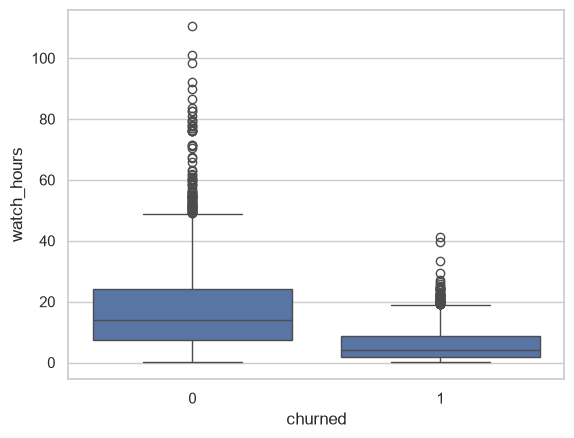

In [93]:
sns.boxplot(x="churned", y="watch_hours", data=df)

#### Observations

- Retained customers exhibit substantially higher watch hours than churned customers.
- The median watch time of retained customers is significantly greater than that of churned customers.
- Although both groups contain outliers, retained customers include substantially more highly engaged users.

#### Business Insight

Customer engagement appears to have a strong relationship with retention. Customers who spend more time watching content are considerably less likely to churn, suggesting that increasing user engagement through personalized recommendations and content discovery may improve subscriber retention.

### LAST LOGIN DAYS VS CHURN

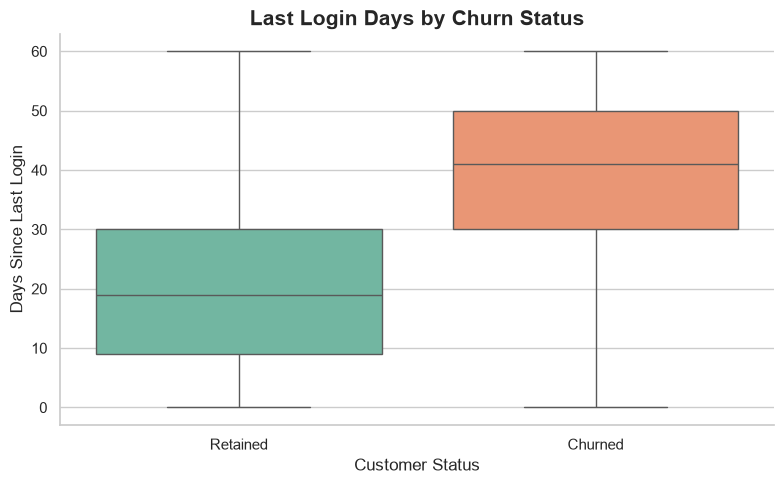

In [94]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="churned",
    y="last_login_days",
    hue="churned",
    palette="Set2",
    legend=False
)

plt.title("Last Login Days by Churn Status", fontsize=15, weight="bold")
plt.xlabel("Customer Status")
plt.ylabel("Days Since Last Login")

plt.xticks([0,1], ["Retained", "Churned"])

sns.despine()
plt.tight_layout()
plt.show()

In [95]:
df.groupby("churned")["last_login_days"].describe()

,count,mean,std,min,25%,50%,75%,max
churned,,,,,,,,
0,2485.0,21.771026,16.155030,0.0,9.0,19.0,30.0,60.0
1,2515.0,38.309344,14.751904,0.0,30.0,41.0,50.0,60.0


In [96]:

df.groupby("churned")["last_login_days"].median()

churned
0    19.0
1    41.0
Name: last_login_days, dtype: float64

In [97]:
retained = df[df["churned"]==0]["last_login_days"].mean()
churned = df[df["churned"]==1]["last_login_days"].mean()

increase = ((churned-retained)/retained)*100
print(increase)

75.9648059775393


1. Chuned customers had **75.96%** longer incactivity periods than retianed customers.
2. The median last login increased from **19** to **41** days, while the mean increased from **21.77** to **38.3**, indicating that customers who remained inactive for longer periods were substantially more likely to churn 

### AVERAGE WATCH TIME PER DAY VS CHURN

In [98]:
df[["watch_hours","avg_watch_time_per_day"]].corr()

,watch_hours,avg_watch_time_per_day
watch_hours,1.000000,0.349742
avg_watch_time_per_day,0.349742,1.000000


In [99]:
df.groupby("churned")["avg_watch_time_per_day"].describe()

,count,mean,std,min,25%,50%,75%,max
churned,,,,,,,,
0,2485.0,1.594133,3.570493,0.0,0.40,0.72,1.46,98.42
1,2515.0,0.164048,0.186164,0.0,0.06,0.12,0.23,4.32


#### Observations

- Retained customers watch substantially more content per day than churned customers.
- The average daily watch time decreases from **1.59 hours** for retained customers to **0.16 hours** for churned customers, representing an approximate **90% reduction**.
- The difference is also reflected in the median values (0.72 vs. 0.12 hours), indicating consistently lower engagement among churned customers.

#### Business Insight

Daily engagement is strongly associated with customer retention. Customers with consistently low daily watch time are considerably more likely to churn, suggesting that personalized content recommendations and engagement campaigns targeting low-activity users may help improve retention.

###  Subscription Type vs Customer Churn

In [100]:
subscription_churn =( 
    pd.crosstab(
        df["subscription_type"],
        df["churned"],
        normalize = "index"
    ) * 100
)

subscription_churn


churned,0,1
subscription_type,,
Basic,38.169777,61.830223
Premium,56.290608,43.709392
Standard,54.556501,45.443499


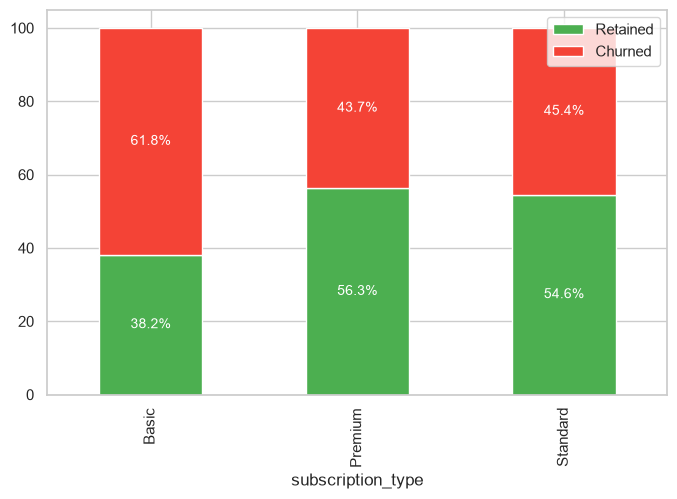

In [101]:
ax = subscription_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8,5),
    color=["#4CAF50", "#F44336"]
)

for container in ax.containers:
    labels = [f"{v.get_height():.1f}%" if v.get_height() > 0 else "" for v in container]
    ax.bar_label(container, labels=labels, label_type="center", color="white", fontsize=10)
plt.legend(["Retained","Churned"])

In [102]:
subscription_churn.round(2)

churned,0,1
subscription_type,,
Basic,38.17,61.83
Premium,56.29,43.71
Standard,54.56,45.44


#### Observations

- Basic subscribers exhibit the highest churn rate, with **61.83%** of customers cancelling their subscriptions.
- Premium subscribers have the lowest churn rate (**43.71%**), while Standard subscribers fall in between (**45.44%**).
- Customer retention generally improves with higher subscription tiers.

#### Business Insight

Subscription type appears to be associated with customer retention. Customers subscribed to higher-tier plans exhibit lower churn rates, suggesting that greater perceived value or engagement may contribute to improved retention. This indicates that encouraging upgrades to higher-value plans could potentially reduce customer churn.

### ADDITIONAL CATEGORICAL FACTORS 

In [103]:
region_churn = (
    pd.crosstab(
        df["region"],
        df["churned"],
        normalize="index"
    ) * 100
)

region_churn

churned,0,1
region,,
Africa,51.681196,48.318804
Asia,49.346017,50.653983
Europe,48.327566,51.672434
North America,50.528790,49.471210
Oceania,49.934641,50.065359
South America,48.568156,51.431844


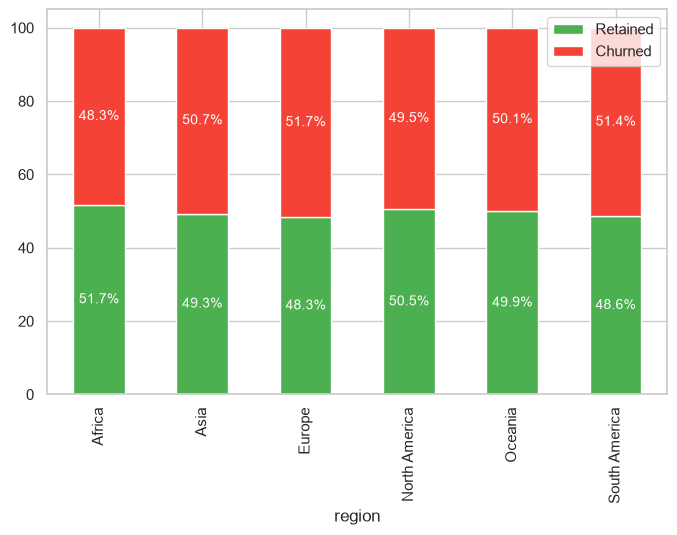

In [104]:
ax = region_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8,5),
    color=["#4CAF50", "#F44336"]
)

for container in ax.containers:
    labels = [f"{v.get_height():.1f}%" if v.get_height() > 0 else "" for v in container]
    ax.bar_label(container, labels=labels, label_type="center", color="white", fontsize=10)
plt.legend(["Retained","Churned"])

In [105]:
device_churn = pd.crosstab(
    df["device"],
    df["churned"],
    normalize="index"
) * 100

device_churn

churned,0,1
device,,
Desktop,50.790306,49.209694
Laptop,48.210736,51.789264
Mobile,49.501992,50.498008
TV,50.050352,49.949648
Tablet,50.000000,50.000000


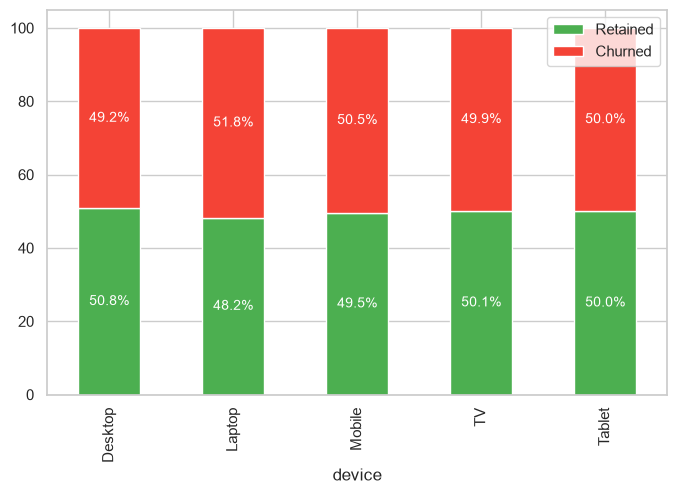

In [106]:
ax = device_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8,5),
    color=["#4CAF50", "#F44336"]
)

for container in ax.containers:
    labels = [f"{v.get_height():.1f}%" if v.get_height() > 0 else "" for v in container]
    ax.bar_label(container, labels=labels, label_type="center", color="white", fontsize=10)
plt.legend(["Retained","Churned"])

In [107]:
payment_churn = pd.crosstab(
    df["payment_method"],
    df["churned"],
    normalize="index"
) * 100

payment_churn

churned,0,1
payment_method,,
Credit Card,56.423433,43.576567
Crypto,40.301508,59.698492
Debit Card,56.310680,43.689320
Gift Card,42.213115,57.786885
PayPal,52.923977,47.076023


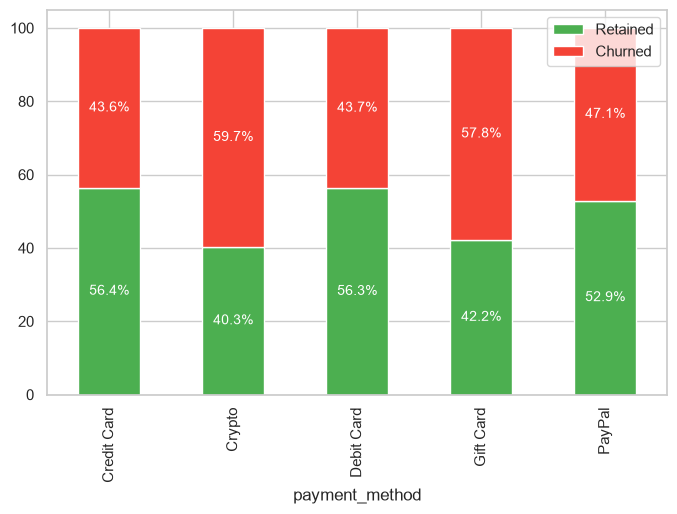

In [108]:
ax = payment_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8,5),
    color=["#4CAF50", "#F44336"]
)

for container in ax.containers:
    labels = [f"{v.get_height():.1f}%" if v.get_height() > 0 else "" for v in container]
    ax.bar_label(container, labels=labels, label_type="center", color="white", fontsize=10)
plt.legend(["Retained","Churned"])

#### Additional Categorical Factors

The relationship between customer churn and region, device type, and payment method was further examined using normalized churn rates to identify whether operational or demographic factors influence customer retention.

##### Observations

- Customer churn remained relatively consistent across different **regions**, indicating that geographical location had minimal influence on subscriber retention.
- Similarly, customers exhibited comparable churn rates across all **device types**, suggesting that the choice of viewing device was not a significant factor in customer cancellations.
- **Payment method**, however, showed a more noticeable association with churn. Customers using **Crypto (59.70%)** and **Gift Cards (57.79%)** experienced the highest churn rates, while **Credit Card (43.58%)** and **Debit Card (43.69%)** users demonstrated the lowest churn rates.

##### Business Insight

Region and device type appear to have limited predictive value for customer churn in this dataset. In contrast, payment method shows a stronger association with customer retention and may serve as a useful feature in predictive modeling. However, this relationship represents an association rather than causation, and further investigation would be required to understand the underlying reasons behind these differences.

## CORRELATION HEATMAP

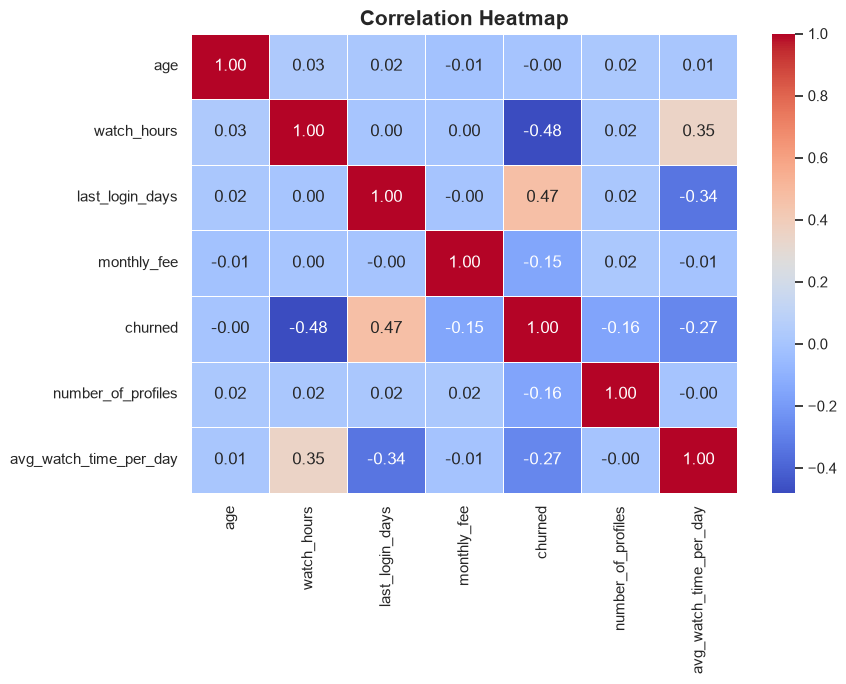

In [109]:
plt.figure(figsize=(9,7))

corr = df.select_dtypes(include="number").corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap", fontsize=15, weight="bold")

plt.tight_layout()
plt.show()

### Observations

- **Watch Hours** exhibits the strongest negative correlation with churn (**-0.48**), indicating that customers who spend more time watching content are less likely to cancel their subscriptions.
- **Last Login Days** shows the strongest positive correlation with churn (**0.47**), suggesting that prolonged inactivity is strongly associated with customer cancellations.
- **Average Watch Time per Day** also demonstrates a moderate negative correlation with churn (**-0.27**), reinforcing the importance of customer engagement.
- Other numerical features, including **Age**, **Monthly Fee**, and **Number of Profiles**, exhibit weak correlations with churn, indicating limited predictive value when considered individually.

#### Business Insight

The correlation analysis supports the findings from the exploratory analysis. Customer engagement metrics—particularly watch hours and inactivity—are the strongest numerical indicators of churn, while demographic characteristics contribute relatively little to explaining customer cancellations. These findings justify prioritizing engagement-related features during predictive modeling.

In [110]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df["subscription_type"], df["churned"])

chi2, p, dof, expected = chi2_contingency(table)

print(f"Chi-square Statistic: {chi2:.2f}")
print(f"P-value: {p:.4e}")

Chi-square Statistic: 133.28
P-value: 1.1457e-29


In [111]:
table = pd.crosstab(df["payment_method"], df["churned"])

chi2, p, dof, expected = chi2_contingency(table)

print(f"Chi-square Statistic: {chi2:.2f}")
print(f"P-value: {p:.4e}")

Chi-square Statistic: 96.91
P-value: 4.4784e-20


#### Results

- **Subscription Type vs Churn**
  - Chi-square Statistic = **133.28**
  - p-value < **0.001**
  - A statistically significant association was observed between subscription type and customer churn.

- **Payment Method vs Churn**
  - Chi-square Statistic = **96.91**
  - p-value < **0.001**
  - A statistically significant association was observed between payment method and customer churn.

#### Conclusion

The statistical tests reinforce the exploratory findings by confirming that both subscription type and payment method are significantly associated with customer churn. Together with the engagement metrics identified earlier, these variables will be retained as important predictors during the machine learning stage.

# Predictive Modeling

The objective is to build a machine learning model capable of predicting customer churn using customer demographics, subscription information, and engagement metrics.

Logistic Regression is selected as the baseline classification model because it is simple, interpretable, and well-suited for binary classification problems such as churn prediction.

In [112]:
X = df.drop(columns=["customer_id", "churned"])
y = df["churned"]

print("Features Shape :", X.shape)
print("Target Shape   :", y.shape)

Features Shape : (5000, 12)
Target Shape   : (5000,)


In [113]:
X = pd.get_dummies(
    X,
    columns=[
        "gender",
        "subscription_type",
        "region",
        "device",
        "payment_method",
        "favorite_genre"
    ],
    drop_first=True
)

print(X.shape)
X.head()

(5000, 29)


,age,watch_hours,last_login_days,monthly_fee,number_of_profiles,avg_watch_time_per_day,gender_Male,gender_Other,subscription_type_Premium,subscription_type_Standard,...,payment_method_Crypto,payment_method_Debit Card,payment_method_Gift Card,payment_method_PayPal,favorite_genre_Comedy,favorite_genre_Documentary,favorite_genre_Drama,favorite_genre_Horror,favorite_genre_Romance,favorite_genre_Sci-Fi
0,51,14.73,29,8.99,1,0.49,False,True,False,False,...,False,False,True,False,False,False,False,False,False,False
1,47,0.70,19,13.99,5,0.03,False,True,False,True,...,False,False,True,False,False,False,False,False,False,True
2,27,16.32,10,13.99,2,1.48,False,False,False,True,...,True,False,False,False,False,False,True,False,False,False
3,53,4.51,12,17.99,2,0.35,False,True,True,False,...,True,False,False,False,False,False,False,True,False,False
4,56,1.89,13,13.99,2,0.13,False,True,False,True,...,True,False,False,False,False,False,False,False,False,False


### Feature Encoding

Machine learning algorithms require numerical input features. Therefore, categorical variables were transformed into numerical representations using one-hot encoding.

One-hot encoding creates a binary indicator column for each category while avoiding artificial ordinal relationships between categorical values.

### Train-Test Split

In [114]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size =0.2,
    random_state =42,
    stratify=y
)
print("Training Features :", X_train.shape)
print("Testing Features :", X_test.shape)

print("Training Target :", y_train.shape)
print("Testing Target :", y_test.shape)

Training Features : (4000, 29)
Testing Features : (1000, 29)
Training Target : (4000,)
Testing Target : (1000,)


### Feature Scaling
Numerical features were standardized using StandardScaler to ensure that variables measured on different scales contribute equally during model training.

In [115]:
from sklearn.preprocessing import StandardScaler
numeric_cols = [  
    "age",
    "watch_hours",
    "last_login_days",
    "monthly_fee",
    "number_of_profiles",
    "avg_watch_time_per_day"
]
scaler = StandardScaler()

X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

X_train[numeric_cols].head()

,age,watch_hours,last_login_days,monthly_fee,number_of_profiles,avg_watch_time_per_day
1310,-1.336313,-0.641884,-1.540040,1.166097,1.392519,0.046474
2139,-1.530110,-0.738665,-0.971796,0.082301,-0.726724,-0.245238
3293,-1.659308,-0.334563,1.073881,-1.272445,-1.433138,-0.267117
134,-1.594709,-0.544255,0.732935,-1.272445,0.686105,-0.278056
2619,-1.594709,-0.841388,-1.369567,0.082301,-0.020309,-0.234299


## TRAINING LOGISTIC REGRESSION MODEL

### Logistic Regression Model

Logistic Regression was selected as the baseline classification model because customer churn is a **binary classification problem**, where the objective is to predict whether a customer will **churn (1)** or **be retained (0)**.

The algorithm is computationally efficient, interpretable, and estimates the probability of customer churn, making it well-suited for identifying the key factors influencing customer retention.



In [116]:
from sklearn.linear_model import LogisticRegression
import numpy as np
model = LogisticRegression(random_state = 42)
model.fit(X_train,y_train)

y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)
prob_df = pd.DataFrame(
    np.round(y_prob[:10], 2),
    columns=["Probability of Retention","Probability of churn"]

)
print(y_pred[:10])
prob_df







[0 1 1 1 1 1 1 1 0 1]


,Probability of Retention,Probability of churn
0,1.00,0.00
1,0.01,0.99
2,0.15,0.85
3,0.01,0.99
4,0.01,0.99
5,0.01,0.99
6,0.04,0.96
7,0.00,1.00
8,0.64,0.36
9,0.15,0.85


The model was trained using the processed training dataset and subsequently used to predict churn for previously unseen customers in the testing dataset.

## Model Evaluation

The trained Logistic Regression model was evaluated on the testing dataset using multiple classification metrics.

Since no single metric fully captures model performance, a combination of Accuracy, Precision, Recall, F1-score, ROC-AUC Score, and the Confusion Matrix were used to assess the model's predictive capability.

In [117]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.8870


In [118]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.90      0.87      0.88       497
           1       0.88      0.90      0.89       503

    accuracy                           0.89      1000
   macro avg       0.89      0.89      0.89      1000
weighted avg       0.89      0.89      0.89      1000



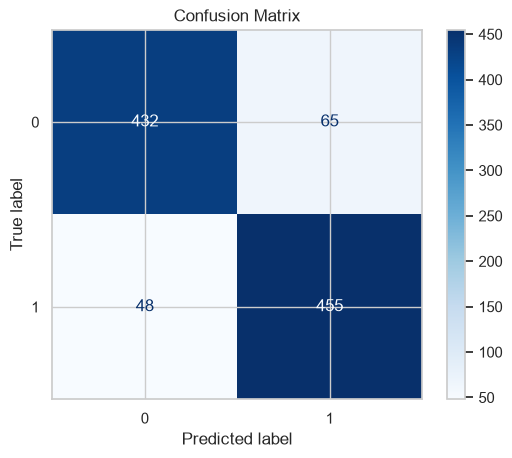

In [119]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)
plt.title("Confusion Matrix")
plt.show()

#### Confusion Matrix Interpretation

The Logistic Regression model correctly classified **432 retained customers** and **455 churned customers**.

Among the incorrect predictions:

- **65 retained customers** were incorrectly classified as churned (False Positives).
- **48 churned customers** were incorrectly classified as retained (False Negatives).

Overall, the model successfully identified the majority of churning customers while maintaining a balanced performance across both classes.

In [120]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, y_prob[:,1])

print(f"ROC-AUC Score : {auc:.4f}")

ROC-AUC Score : 0.9659


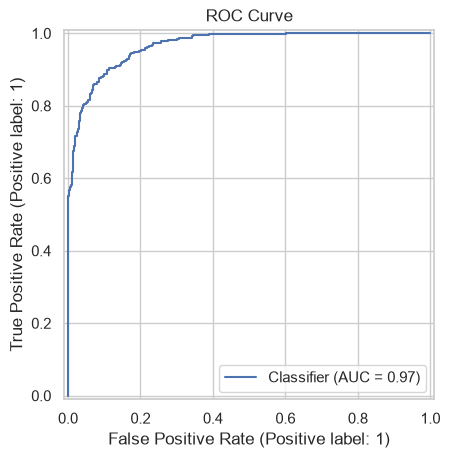

In [121]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob[:,1]
)

plt.title("ROC Curve")
plt.show()

### Model Performance Summary

The Logistic Regression model achieved an **accuracy of 88.7%** on the testing dataset.

Performance remained balanced across both customer classes, achieving high Precision, Recall, and F1-scores for churn prediction.

The model also achieved an **ROC-AUC score of 0.966**, indicating excellent ability to distinguish between retained and churned customers across different classification thresholds.

These results demonstrate that the selected engagement metrics and customer attributes provide strong predictive power for customer churn.

In [122]:
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_[0]
})

coef_df = coef_df.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

coef_df.head(15)

,Feature,Coefficient
5,avg_watch_time_per_day,-4.551146
1,watch_hours,-3.734894
2,last_login_days,2.365461
19,payment_method_Crypto,1.606192
21,payment_method_Gift Card,1.463770
4,number_of_profiles,-1.127370
9,subscription_type_Standard,-1.028451
3,monthly_fee,-0.826875
24,favorite_genre_Documentary,-0.296030
20,payment_method_Debit Card,-0.282267


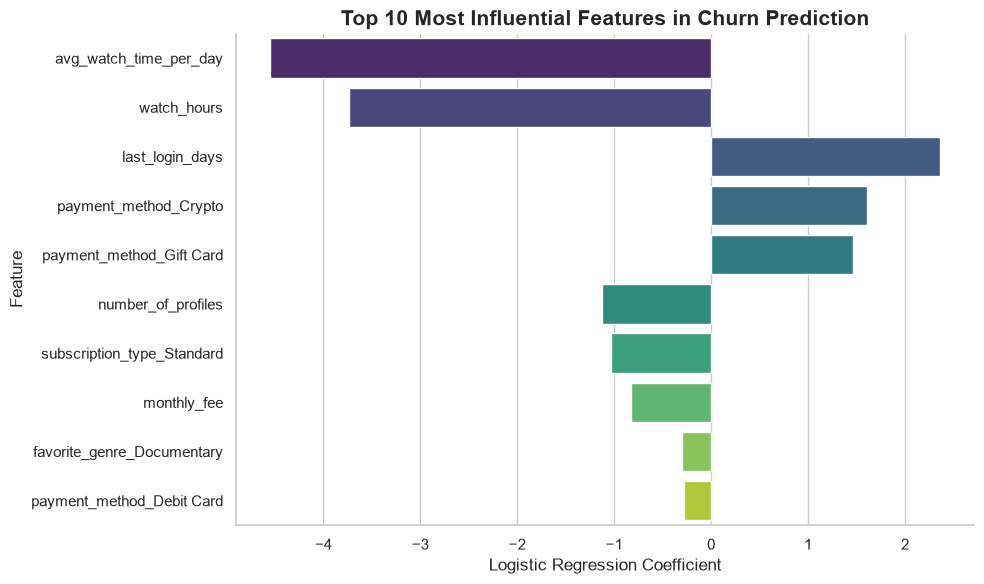

In [123]:
top10 = coef_df.head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top10,
    x="Coefficient",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Most Influential Features in Churn Prediction", fontsize=15, weight="bold")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")

sns.despine()

plt.tight_layout()
plt.show()

## Feature Importance

Logistic Regression coefficients were analyzed to understand which customer attributes had the greatest influence on churn prediction.

### Key Findings

- **Average Watch Time per Day** and **Watch Hours** were the strongest negative predictors of churn, indicating that highly engaged customers are significantly less likely to cancel their subscriptions.
- **Last Login Days** emerged as the strongest positive predictor, highlighting customer inactivity as a major indicator of churn.
- Customers using **Crypto** and **Gift Card** payment methods exhibited a higher likelihood of churn compared to the reference payment category.
- Higher subscription tiers and accounts with multiple profiles were associated with improved customer retention.

### Business Insight

The model confirms that customer engagement is the strongest determinant of subscriber retention. Increasing viewing activity, reducing prolonged inactivity, and encouraging adoption of higher-value subscription plans may help reduce customer churn.

# Business Recommendations

Based on the exploratory analysis and predictive modeling results, the following recommendations are proposed to improve customer retention:

### 1. Identify and Re-engage Inactive Customers

Customer inactivity (measured using **Last Login Days**) was one of the strongest predictors of churn. Automated email notifications, personalized recommendations, and promotional campaigns should target customers who have not logged in for extended periods.

### 2. Increase Customer Engagement

Customers with higher **Watch Hours** and **Average Watch Time per Day** demonstrated significantly lower churn rates. Improving content discovery through personalized recommendations, curated watchlists, and targeted notifications may encourage greater platform engagement.

### 3. Improve the Basic Subscription Experience

The Basic subscription plan exhibited the highest churn rate among all subscription tiers. Evaluating pricing, feature offerings, or introducing upgrade incentives could improve customer retention within this segment.

### 4. Monitor High-Risk Customer Segments

Customers using **Crypto** and **Gift Card** payment methods showed comparatively higher churn rates. While this relationship does not imply causation, these customers may be prioritized for proactive retention campaigns.

### 5. Integrate Churn Prediction into Business Operations

The developed Logistic Regression model can be incorporated into customer relationship management (CRM) workflows to identify high-risk subscribers early and enable targeted retention strategies before cancellation occurs.

# Conclusion

This project explored customer churn in a subscription-based streaming service through exploratory data analysis, statistical hypothesis testing, and predictive modeling.

The analysis identified customer engagement metrics—including **Watch Hours**, **Average Watch Time per Day**, and **Last Login Days**—as the strongest indicators of customer churn. Subscription type and payment method also demonstrated statistically significant associations with customer retention, while region and device type showed minimal influence.

A Logistic Regression model was developed to predict customer churn, achieving:

- **Accuracy:** 88.7%
- **ROC-AUC Score:** 0.966

The model demonstrated strong predictive performance while remaining interpretable, allowing key churn drivers to be identified through feature coefficients.

Overall, the project illustrates how exploratory analysis and machine learning can be combined to understand customer behavior, identify at-risk subscribers, and support data-driven retention strategies.

# Key Takeaways

- Customer engagement is the strongest predictor of subscriber retention.
- Customer inactivity is a major indicator of churn risk.
- Subscription type and payment method exhibit meaningful associations with churn.
- Logistic Regression achieved strong predictive performance (Accuracy: **88.7%**, ROC-AUC: **0.966**).
- Predictive analytics can support proactive customer retention strategies by identifying high-risk subscribers before cancellation.

# Random Forest Classifier

To compare the performance of Logistic Regression, a Random Forest classifier was also trained using the same preprocessed training dataset.



In [124]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_prob = rf_model.predict_proba(X_test)

In [125]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy :", accuracy_score(y_test, rf_pred))

print(classification_report(y_test, rf_pred))

print("ROC-AUC :", roc_auc_score(y_test, rf_prob[:,1]))

Accuracy : 0.983
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       497
           1       0.99      0.98      0.98       503

    accuracy                           0.98      1000
   macro avg       0.98      0.98      0.98      1000
weighted avg       0.98      0.98      0.98      1000

ROC-AUC : 0.9976479153249517


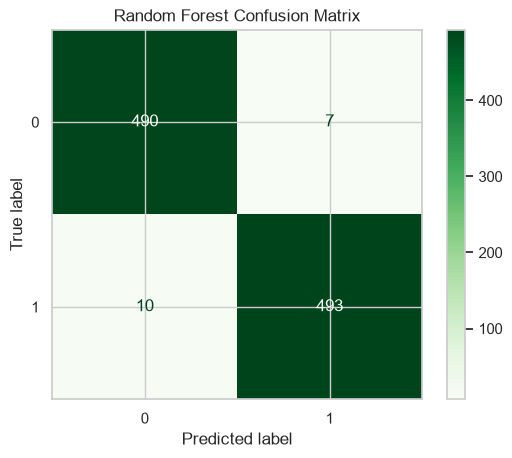

In [126]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    cmap="Greens"
)

plt.title("Random Forest Confusion Matrix")

plt.show()

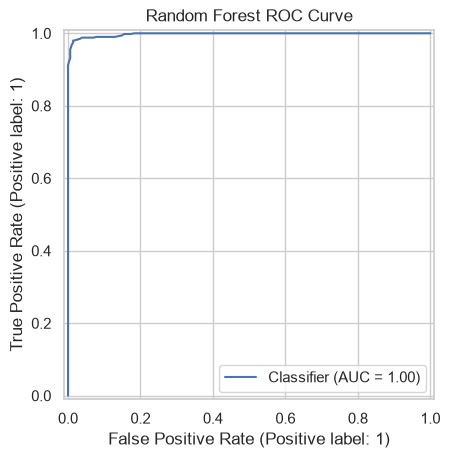

In [127]:
RocCurveDisplay.from_predictions(
    y_test,
    rf_prob[:,1]
)

plt.title("Random Forest ROC Curve")

plt.show()

In [128]:
rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

rf_importance.head(10)

,Feature,Importance
5,avg_watch_time_per_day,0.375306
1,watch_hours,0.203436
2,last_login_days,0.175428
4,number_of_profiles,0.064898
3,monthly_fee,0.027191
0,age,0.026299
19,payment_method_Crypto,0.016749
21,payment_method_Gift Card,0.014594
9,subscription_type_Standard,0.008395
8,subscription_type_Premium,0.007997


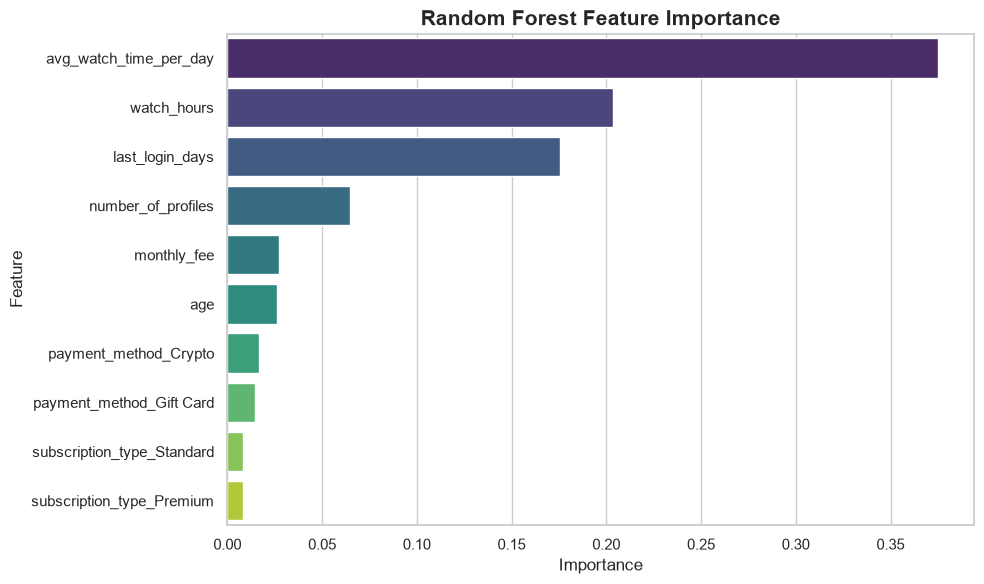

In [129]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=rf_importance.head(10),
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Random Forest Feature Importance", fontsize=15, weight="bold")

plt.tight_layout()

plt.show()

In [130]:
comparison = pd.DataFrame({
    "Model":[
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy":[
        accuracy_score(y_test,y_pred),
        accuracy_score(y_test,rf_pred)
    ],
    "ROC-AUC":[
        roc_auc_score(y_test,y_prob[:,1]),
        roc_auc_score(y_test,rf_prob[:,1])
    ]
})

comparison = comparison.copy()

comparison["Accuracy"] = (comparison["Accuracy"]*100).round(2).astype(str) + "%"

comparison["ROC-AUC"] = comparison["ROC-AUC"].round(3)

comparison

,Model,Accuracy,ROC-AUC
0,Logistic Regression,88.7%,0.966
1,Random Forest,98.3%,0.998


# Model Comparison

To evaluate different approaches for churn prediction, both Logistic Regression and Random Forest classifiers were trained and evaluated on the testing dataset.

| Model | Accuracy | ROC-AUC |
|-------|---------:|--------:|
| Logistic Regression | **88.7%** | **0.966** |
| Random Forest | **98.3%** | **0.998** |

The Random Forest classifier achieved superior predictive performance across all evaluation metrics, reducing the number of misclassifications from **113** to **17** on the testing dataset.

However, Logistic Regression remains valuable due to its interpretability. The learned coefficients clearly identify the direction and relative influence of each feature on customer churn, making it easier to communicate insights to business stakeholders.

Random Forest serves as a high-performance predictive benchmark, while Logistic Regression provides transparent and interpretable decision-making.